# 01 — Análise Exploratória de Dados (EDA)

**Competição:** IEEE-CIS Fraud Detection  
**Dados:** `train_transaction.csv` + `train_identity.csv`

## Sumário

| Seção | Conteúdo |
|--------|----------|
| [1.0](#10-puxando-os-dados) | Puxando os Dados — download, imports (`utils.py`), leitura dos CSVs |
| [2.0](#20-análise-geral-dos-dataframes) | Análise Geral — `info()` e `head(20)` de cada DataFrame |
| [3.0](#30-análise-do-target-e-de-df_train_tr) | Análise de `df_train_tr` — Target, nulos, cardinalidade, Feature Engineering |
| [4.0](#40-análise-do-df_train_id) | Análise de `df_train_id` — nulos, remoção >90%, cardinalidade, Feature Engineering |
| [5.0](#50-downcast-merge-e-análise-multivariada-df_train) | Downcast, Merge e Análise Multivariada (`df_train`) — Correlação de Pares, IV e VIF |

---
## 1.0 Puxando os Dados

Carrega os dados da competição IEEE-CIS Fraud Detection a partir do Kaggle.

In [36]:
import os
import sys

import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Garante que o módulo utils.py seja encontrado na raiz do projeto
sys.path.append(os.path.abspath(".."))
sys.path.append(os.path.abspath("."))

import utils
from utils import (
    plot_target_distribution,
    analisar_tipos_colunas,
    analisar_valores_nulos,
    analisar_nulos_por_faixa,
    analisar_valores_unicos,
    analisar_baixa_cardinalidade,
    safe_downcast,
    analise_correlacao_pares,
    analise_correlação_pares,
    calcular_iv_dataset,
    analisar_vif,
)

import warnings
warnings.filterwarnings("ignore")


In [3]:
DIR_ARQ = os.path.join(os.getcwd(), "data", "raw")
os.makedirs(DIR_ARQ, exist_ok=True)

In [6]:
kagglehub.login()

In [7]:
path = kagglehub.competition_download(
    "ieee-fraud-detection",
    force_download=True,
    output_dir=DIR_ARQ,
)

print("Path to competition files:", path)

100%|██████████| 118M/118M [00:00<00:00, 203MB/s]  

Extracting files...


Path to competition files: /content/data/raw


In [8]:
df_train_id = pd.read_csv(os.path.join(DIR_ARQ, "train_identity.csv"))
df_train_tr = pd.read_csv(os.path.join(DIR_ARQ, "train_transaction.csv"))

---
## 2.0 Análise Geral dos DataFrames

Visão geral da estrutura: tipos, dimensões e primeiras linhas de cada DataFrame.

In [9]:
df_train_tr.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 590540 entries, 0 to 590539
Columns: 394 entries, TransactionID to V339
dtypes: float64(376), int64(4), object(14)
memory usage: 1.7+ GB


In [10]:
df_train_tr.head(20)


,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,V330,V331,V332,V333,V334,V335,V336,V337,V338,V339
0,2987000,0,86400,68.500,W,13926,NaN,150.0,discover,142.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.000,W,2755,404.0,150.0,mastercard,102.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.000,W,4663,490.0,150.0,visa,166.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.000,W,18132,567.0,150.0,mastercard,117.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.000,H,4497,514.0,150.0,mastercard,102.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,2987005,0,86510,49.000,W,5937,555.0,150.0,visa,226.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,2987006,0,86522,159.000,W,12308,360.0,150.0,visa,166.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,2987007,0,86529,422.500,W,12695,490.0,150.0,visa,226.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,2987008,0,86535,15.000,H,2803,100.0,150.0,visa,226.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9,2987009,0,86536,117.000,W,17399,111.0,150.0,mastercard,224.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [11]:
df_train_id.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 144233 entries, 0 to 144232
Data columns (total 41 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   TransactionID  144233 non-null  int64  
 1   id_01          144233 non-null  float64
 2   id_02          140872 non-null  float64
 3   id_03          66324 non-null   float64
 4   id_04          66324 non-null   float64
 5   id_05          136865 non-null  float64
 6   id_06          136865 non-null  float64
 7   id_07          5155 non-null    float64
 8   id_08          5155 non-null    float64
 9   id_09          74926 non-null   float64
 10  id_10          74926 non-null   float64
 11  id_11          140978 non-null  float64
 12  id_12          144233 non-null  object 
 13  id_13          127320 non-null  float64
 14  id_14          80044 non-null   float64
 15  id_15          140985 non-null  object 
 16  id_16          129340 non-null  object 
 17  id_17          139369 non-nul

In [12]:
df_train_id.head(20)


,TransactionID,id_01,id_02,id_03,id_04,id_05,id_06,id_07,id_08,id_09,...,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
0,2987004,0.0,70787.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,samsung browser 6.2,32.0,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M
1,2987008,-5.0,98945.0,NaN,NaN,0.0,-5.0,NaN,NaN,NaN,...,mobile safari 11.0,32.0,1334x750,match_status:1,T,F,F,T,mobile,iOS Device
2,2987010,-5.0,191631.0,0.0,0.0,0.0,0.0,NaN,NaN,0.0,...,chrome 62.0,NaN,NaN,NaN,F,F,T,T,desktop,Windows
3,2987011,-5.0,221832.0,NaN,NaN,0.0,-6.0,NaN,NaN,NaN,...,chrome 62.0,NaN,NaN,NaN,F,F,T,T,desktop,NaN
4,2987016,0.0,7460.0,0.0,0.0,1.0,0.0,NaN,NaN,0.0,...,chrome 62.0,24.0,1280x800,match_status:2,T,F,T,T,desktop,MacOS
5,2987017,-5.0,61141.0,3.0,0.0,3.0,0.0,NaN,NaN,3.0,...,chrome 62.0,24.0,1366x768,match_status:2,T,F,T,T,desktop,Windows
6,2987022,-15.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,2987038,0.0,31964.0,0.0,0.0,0.0,-10.0,NaN,NaN,0.0,...,chrome 62.0,32.0,1920x1080,match_status:2,T,F,T,T,mobile,NaN
8,2987040,-10.0,116098.0,0.0,0.0,0.0,0.0,NaN,NaN,0.0,...,chrome 62.0,NaN,NaN,NaN,F,F,T,T,desktop,Windows
9,2987048,-5.0,257037.0,NaN,NaN,0.0,0.0,NaN,NaN,NaN,...,chrome 62.0,NaN,NaN,NaN,F,F,T,T,desktop,Windows


---
## 3.0 Análise do Target e de `df_train_tr`

Distribuição do target `isFraud`, contagem por tipo de dado, valores nulos, cardinalidade e Feature Engineering.

> **Pipeline de Storytelling — `df_train_tr` (6 passos):**
> | Passo | Conteúdo |
> |-------|----------|
> | 3.1 | Contagem de colunas & Distribuição do Target (Quantidade e %) |
> | 3.2 | Análise de valores nulos (faixas de 5% e top variáveis) |
> | 3.3 | Valores únicos por coluna (cardinalidade) |
> | 3.4 | Distribuições de baixa cardinalidade (≤5) |
> | 3.5 | Feature Engineering (flags M, card, V, tempo, centavos, email) |
> | 3.6 | Downcast (executado no merge — Seção 5.0) |

### 3.1 — Contagem de Colunas & Target

--- Contagem de Colunas por Tipo (df_train_tr) ---
  Colunas numéricas inteiras : 4
  Colunas numéricas float    : 376
  Total de colunas numéricas : 380
  Colunas categóricas        : 14
  Total geral de colunas     : 394

--- Distribuição do Target (isFraud) ---
  isFraud=0 (Legítima / Adimplente):    569,877  (96.501%)
  isFraud=1 (Fraude / Default):          20,663  (3.499%)
  Valores nulos no target:                        0
  Ratio (0:1):                                 27.6:1



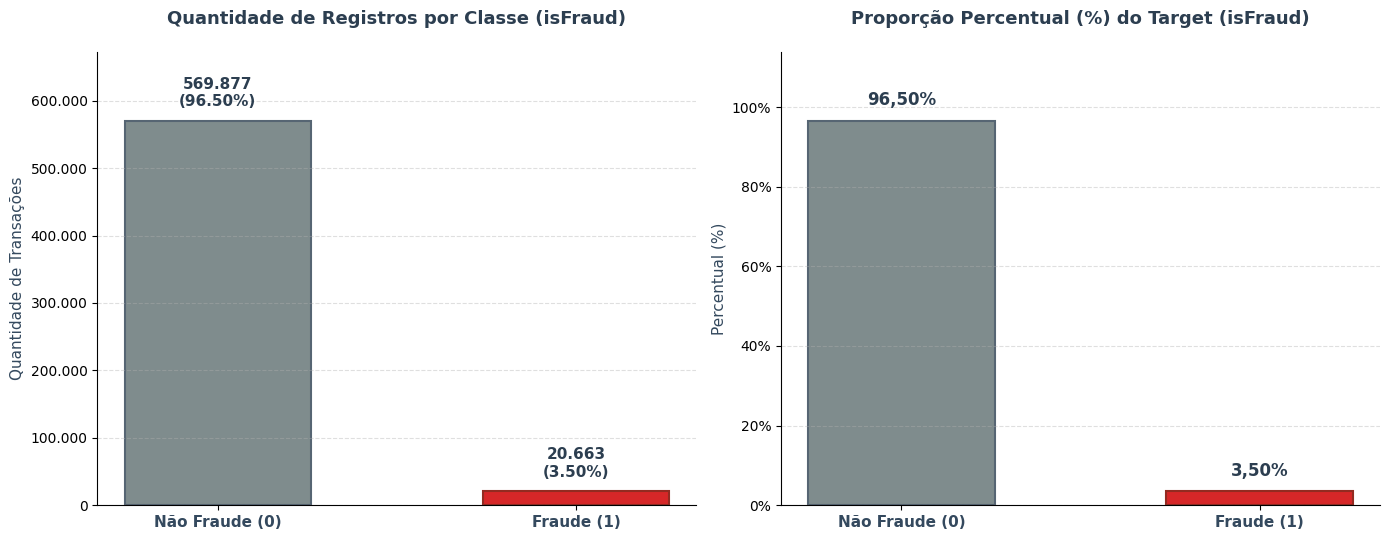

In [13]:
# Contagem de colunas numéricas e categóricas + distribuição do target (Quantidade e % rotulados)
resumo_tipos_tr = analisar_tipos_colunas(df_train_tr, nome_df="df_train_tr")
print()
target_counts, target_pct, ratio = plot_target_distribution(df_train_tr, target_col="isFraud")

>
> ### 3,5% de target: a classe é desbalanceada e precisam ser adotadas estratégias de balanceamento/pesos
>
> ### Há poucas colunas categóricas, vamos analisá-las junto aos nulos e cardinalidade
>

### 3.2 — Análise de Valores Nulos (faixas de 5%)

In [14]:
# Agrupamento de nulos em 20 faixas de 5% (0% a 100%) via utils.py
analise_bins_tr = analisar_nulos_por_faixa(df_train_tr, n_faixas=20)
display(analise_bins_tr)

,faixa_nulos,qtd_colunas,exemplos,pct_do_total_colunas
0,"(-0.001, 5.0]",112,"TransactionID, isFraud, TransactionDT",28.43
1,"(5.0, 10.0]",0,,0.00
2,"(10.0, 15.0]",48,"addr1, addr2, D10",12.18
3,"(15.0, 20.0]",22,"P_emaildomain, D15, V75",5.58
4,"(20.0, 25.0]",0,,0.00
5,"(25.0, 30.0]",20,"D4, M6, V35",5.08
6,"(30.0, 35.0]",0,,0.00
7,"(35.0, 40.0]",0,,0.00
8,"(40.0, 45.0]",1,D3,0.25
9,"(45.0, 50.0]",17,"D2, D11, M1",4.31


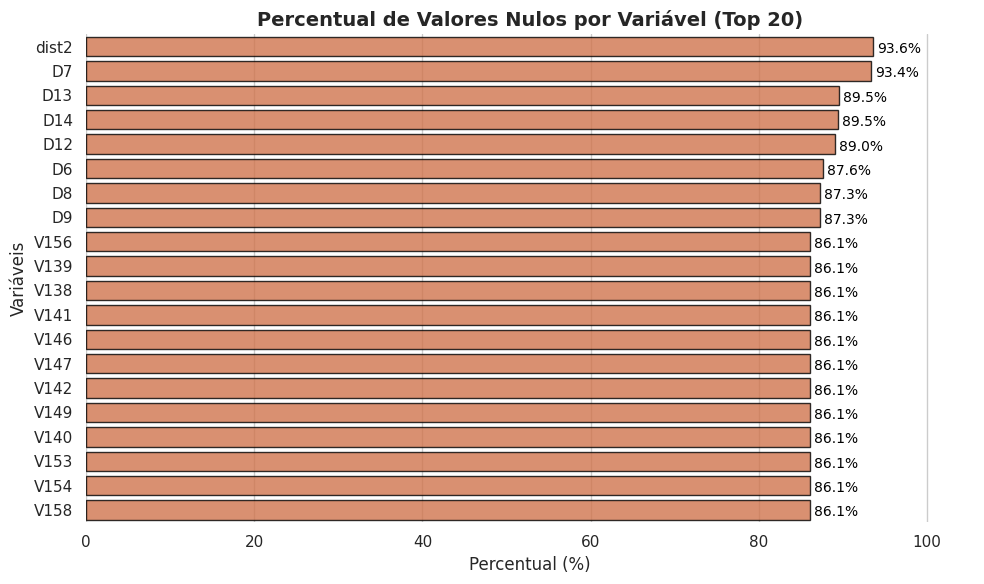

In [ ]:
# Tabela detalhada e gráfico das Top 20 variáveis com mais nulos em df_train_tr
df_nulos_tr = analisar_valores_nulos(df_train_tr, plotar=False, top_n=20)

### 3.3 — Análise de Valores Únicos

In [16]:
# Valores únicos por coluna (menor cardinalidade primeiro)
df_unicos_tr = analisar_valores_unicos(df_train_tr, top_n=35)

,coluna,valores_unicos
0,isFraud,2
1,M1,3
2,M3,3
3,M2,3
4,M7,3
5,M6,3
6,M8,3
7,M5,3
8,V1,3
9,V107,3


### 3.4 — Distribuições de Baixa Cardinalidade (≤5)

In [17]:
# Distribuição percentual das colunas com até 5 valores únicos
colunas_baixa_card_tr = analisar_baixa_cardinalidade(df_train_tr, df_unicos=df_unicos_tr, max_unicos=5)

Total de colunas com cardinalidade <= 5: 33

--- Distribuição da coluna: isFraud ---
isFraud
0    96.5
1     3.5

--- Distribuição da coluna: M1 ---
M1
T      54.09
NaN    45.91
F       0.00

--- Distribuição da coluna: M3 ---
M3
NaN    45.91
T      42.63
F      11.47

--- Distribuição da coluna: M2 ---
M2
T      48.34
NaN    45.91
F       5.75

--- Distribuição da coluna: M7 ---
M7
NaN    58.64
F      35.79
T       5.57

--- Distribuição da coluna: M6 ---
M6
F      38.58
T      32.74
NaN    28.68

--- Distribuição da coluna: M8 ---
M8
NaN    58.63
F      26.29
T      15.08

--- Distribuição da coluna: M5 ---
M5
NaN    59.35
F      22.44
T      18.22

--- Distribuição da coluna: V1 ---
V1
1.0    52.70
NaN    47.29
0.0     0.00

--- Distribuição da coluna: V107 ---
V107
1.0    99.90
NaN     0.05
0.0     0.04

--- Distribuição da coluna: V14 ---
V14
1.0    87.07
NaN    12.88
0.0     0.04

--- Distribuição da coluna: V41 ---
V41
1.0    71.34
NaN    28.61
0.0     0.05

--- Distribuição da 

### 3.5 — Feature Engineering (`df_train_tr`)

In [18]:
# ==============================================================================
# 1. BLOCO M: FLAGS DE VALIDAÇÃO DE CADASTRO (M1 a M9)
# ==============================================================================
cols_m_bool = ['M1', 'M2', 'M3', 'M5', 'M6', 'M7', 'M8', 'M9']

# 1.1 Contagem de correspondências bem-sucedidas ('T') e falhas ('F')
# Compradores legítimos acumulam mais 'T'; fraudadores concentram mais 'F' ou NaNs
df_train_tr['M_true_count'] = (df_train_tr[cols_m_bool] == 'T').sum(axis=1).astype('int8')
df_train_tr['M_false_count'] = (df_train_tr[cols_m_bool] == 'F').sum(axis=1).astype('int8')

# 1.2 Assinatura conjunta do primeiro bloco de checkout (M1, M2, M3)
df_train_tr['M1_M2_M3_assinatura'] = (
    df_train_tr['M1'].fillna('X') + '_' +
    df_train_tr['M2'].fillna('X') + '_' +
    df_train_tr['M3'].fillna('X')
)

# 1.3 M4 tratado como categoria explícita (preservando NaN como 'Missing')
df_train_tr['M4_limpo'] = df_train_tr['M4'].fillna('Missing').astype('category')


# ==============================================================================
# 2. COMBINAÇÃO E LIMPEZA DE CARTÃO (card4 e card6)
# ==============================================================================
# 2.1 Agrupamento de categorias ultra-raras em card6 para evitar split quebrado no CV
df_train_tr['card6_limpo'] = df_train_tr['card6'].replace({
    'debit or credit': 'debit',
    'charge card': 'credit'
}).fillna('missing')

# 2.2 Combinação Bandeira + Tipo (ex: 'visa_debit', 'mastercard_credit')
df_train_tr['card_brand_type'] = (
    df_train_tr['card4'].fillna('missing') + '_' + df_train_tr['card6_limpo']
).astype('category')


# ==============================================================================
# 3. ANOMALIAS CRÍTICAS E TRATAMENTO NO BLOCO V
# ==============================================================================
# 3.1 Flag da anomalia rara em V14 (quando V14 == 0, o risco dispara)
df_train_tr['is_V14_zero'] = (df_train_tr['V14'] == 0.0).astype('int8')

# 3.2 Indicador de anomalia no bloco quase-constante (V107, V117-V122)
# Registra transações que saíram do padrão universal de 1.0
cols_near_const = ['V107', 'V117', 'V118', 'V119', 'V120', 'V121', 'V122']
df_train_tr['V_near_constant_anomaly'] = (
    (df_train_tr[cols_near_const] != 1.0) & df_train_tr[cols_near_const].notnull()
).any(axis=1).astype('int8')

# 3.3 Remoção de coluna estritamente inútil (variância zero)
# V305 tem 100.0% das observações válidas em 1.0
if 'V305' in df_train_tr.columns:
    df_train_tr.drop(columns=['V305'], inplace=True)


# ==============================================================================
# 4. MAPEAMENTO DE VALIDAÇÕES BOOLEANAS DO BLOCO M
# ==============================================================================
# Mapeamento numérico preservando NaN para árvores (T=1, F=0)
map_tf = {'T': 1, 'F': 0}
for col in cols_m_bool:
    df_train_tr[f'{col}_num'] = df_train_tr[col].map(map_tf)

print("Novas features de tr geradas:")
print([c for c in df_train_tr.columns if any(p in c for p in ['M_', 'card_', 'is_V14', 'V_near', '_limpo'])])

Novas features de tr geradas:
['M_true_count', 'M_false_count', 'M4_limpo', 'card6_limpo', 'card_brand_type', 'is_V14_zero', 'V_near_constant_anomaly']


In [19]:
# 1.1 Variáveis Temporais (Transação em segundos transformada em horas e dias da semana)
# O dataset cobre 6 meses; a hora do dia isola comportamentos de bots noturnos
df_train_tr['Transaction_Hour'] = (df_train_tr['TransactionDT'] // 3600) % 24
df_train_tr['Transaction_DayOfWeek'] = (df_train_tr['TransactionDT'] // (3600 * 24)) % 7

# 1.2 Análise de Centavos
# Extrai apenas a parte decimal. Transações cambiais de fraude costumam ter dízimas.
df_train_tr['TransactionAmt_Cents'] = np.modf(df_train_tr['TransactionAmt'])[0]

# 1.3 Engenharia de Domínios de E-mail
# Cria flag se comprador e vendedor usam o mesmo domínio
df_train_tr['same_email_domain'] = (
    (df_train_tr['P_emaildomain'] == df_train_tr['R_emaildomain']) & 
    df_train_tr['P_emaildomain'].notnull()
).astype('int8')

# Extrai o sufixo (com, net, mx) que frequentemente isola origens de risco
df_train_tr['P_email_suffix'] = df_train_tr['P_emaildomain'].str.split('.').str[-1]

# 1.4 Contagem Global e Flags de Presença
cols_tr_features = [c for c in df_train_tr.columns if c not in ['TransactionID', 'isFraud']]
df_train_tr['tr_null_count'] = df_train_tr[cols_tr_features].isnull().sum(axis=1).astype('int16')
df_train_tr['has_dist2'] = df_train_tr['dist2'].notnull().astype('int8')
df_train_tr['has_R_email'] = df_train_tr['R_emaildomain'].notnull().astype('int8')

In [20]:
df_train_tr.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 590540 entries, 0 to 590539
Columns: 417 entries, TransactionID to has_R_email
dtypes: category(2), float64(384), int16(1), int64(6), int8(7), object(17)
memory usage: 1.8+ GB


### 3.6 — Downcast (executado no merge — ver Seção 5.0)

---
## 4.0 Análise do `df_train_id`

Contagem por tipo, valores nulos, tratamento de colunas esparsas (>90%), cardinalidade, distribuições de baixa cardinalidade e Feature Engineering.

> **Pipeline de Storytelling — `df_train_id` (6 passos):**
> | Passo | Conteúdo |
> |-------|----------|
> | 4.1 | Contagem de colunas por tipo |
> | 4.2 | Análise de valores nulos (ranking e faixas de 5%) |
> | 4.3 | Remoção de colunas com >90% nulos e criação de flags |
> | 4.4 | Valores únicos por coluna (cardinalidade) |
> | 4.5 | Distribuições de baixa cardinalidade (≤5) |
> | 4.6 | Feature Engineering (`df_train_id`) |

### 4.1 — Contagem de Colunas

In [21]:
# Contagem de colunas numéricas e categóricas em df_train_id
resumo_tipos_id = analisar_tipos_colunas(df_train_id, nome_df="df_train_id")

--- Contagem de Colunas por Tipo (df_train_id) ---
  Colunas numéricas inteiras : 1
  Colunas numéricas float    : 23
  Total de colunas numéricas : 24
  Colunas categóricas        : 17
  Total geral de colunas     : 41


### 4.2 — Análise de Valores Nulos

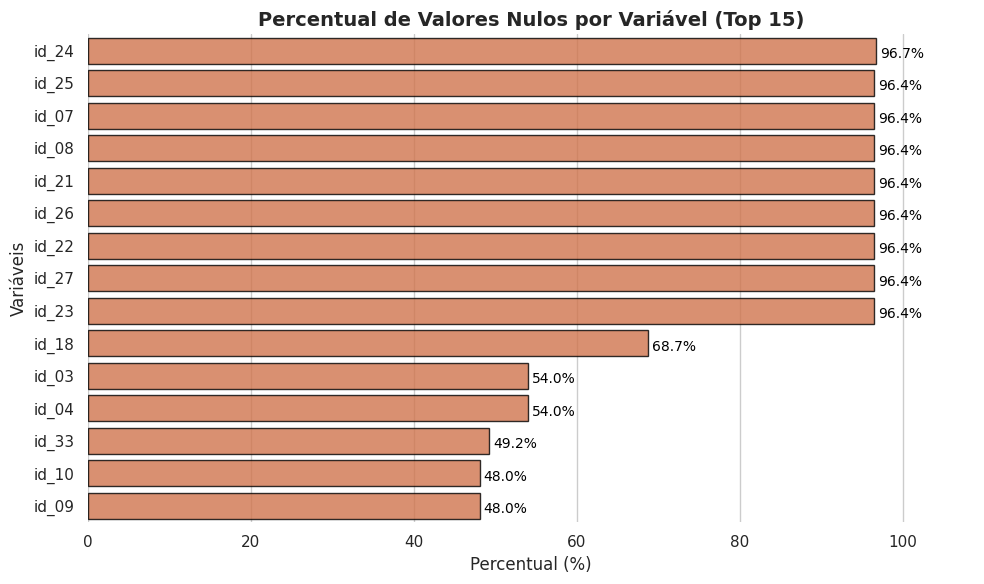

,Total Nulos,Percentual (%),Tipo de Dado
id_24,139486,96.71,float64
id_25,139101,96.44,float64
id_07,139078,96.43,float64
id_08,139078,96.43,float64
id_21,139074,96.42,float64
id_26,139070,96.42,float64
id_22,139064,96.42,float64
id_27,139064,96.42,object
id_23,139064,96.42,object
id_18,99120,68.72,float64


,faixa_nulos,qtd_colunas,exemplos,pct_do_total_colunas
0,"(-0.001, 5.0]",17,"TransactionID, id_01, id_02",41.46
1,"(5.0, 10.0]",2,"id_05, id_06",4.88
2,"(10.0, 15.0]",2,"id_13, id_16",4.88
3,"(15.0, 20.0]",1,DeviceInfo,2.44
8,"(40.0, 45.0]",1,id_14,2.44
9,"(45.0, 50.0]",6,"id_09, id_10, id_30",14.63
10,"(50.0, 55.0]",2,"id_03, id_04",4.88
13,"(65.0, 70.0]",1,id_18,2.44
19,"(95.0, 100.0]",9,"id_07, id_08, id_21",21.95


In [ ]:
# Análise de valores nulos por variável e por faixas de 5%
df_nulos_id = analisar_valores_nulos(df_train_id, plotar=False, top_n=15)
display(df_nulos_id.head(10))

analise_bins_id = analisar_nulos_por_faixa(df_train_id, n_faixas=20)
display(analise_bins_id[analise_bins_id["qtd_colunas"] > 0])

### 4.3 — Remoção de Colunas com >90% Nulos

In [23]:
# Tratando os nulos removendo os de > 90% e criando uma FLAG com numero de valores nulos

# Hipótese: Muitos valores nulos indicam maior probabilidade de fraude

# 1. Cria a meta-feature de contagem de nulos na identidade
df_train_id['id_null_count'] = df_train_id.isnull().sum(axis=1)

# 2. Sintetiza o bloco esparso (id_07, id_08, id_21 a id_27) em uma flag única
if 'id_23' in df_train_id.columns:
    df_train_id['has_advanced_network_check'] = df_train_id['id_23'].notnull().astype('int8')

# 3. Lista de colunas esparsas para descarte definitivo (>90% de nulos em df_id)
cols_to_drop = ['id_07', 'id_08', 'id_21', 'id_22', 'id_23', 'id_24', 'id_25', 'id_26', 'id_27']
df_train_id = df_train_id.drop(columns=cols_to_drop, errors='ignore')

print(f"Colunas restantes em df_train_id:{df_train_id.shape[1]}")

Colunas restantes em df_train_id:34


### 4.4 — Análise de Valores Únicos

In [24]:
# Valores únicos por coluna em df_train_id
df_unicos_id = analisar_valores_unicos(df_train_id, top_n=20)

,coluna,valores_unicos
0,id_12,2
1,has_advanced_network_check,2
2,id_38,3
3,id_16,3
4,DeviceType,3
5,id_35,3
6,id_29,3
7,id_37,3
8,id_36,3
9,id_28,3


>
> **Veja que é interessante analisar o que tem de valor único nas colunas com cardinalidade até 5**
>

### 4.5 — Distribuições de Baixa Cardinalidade (≤5)

In [25]:
# Distribuição das colunas com até 5 valores únicos em df_train_id
colunas_baixa_card_id = analisar_baixa_cardinalidade(df_train_id, df_unicos=df_unicos_id, max_unicos=5)

Total de colunas com cardinalidade <= 5: 13

--- Distribuição da coluna: id_12 ---
id_12
NotFound    85.3
Found       14.7

--- Distribuição da coluna: has_advanced_network_check ---
has_advanced_network_check
0    96.42
1     3.58

--- Distribuição da coluna: id_38 ---
id_38
F      51.25
T      46.50
NaN     2.25

--- Distribuição da coluna: id_16 ---
id_16
Found       45.98
NotFound    43.69
NaN         10.33

--- Distribuição da coluna: DeviceType ---
DeviceType
desktop    59.05
mobile     38.58
NaN         2.37

--- Distribuição da coluna: id_35 ---
id_35
T      53.95
F      43.80
NaN     2.25

--- Distribuição da coluna: id_29 ---
id_29
Found       51.95
NotFound    45.80
NaN          2.26

--- Distribuição da coluna: id_37 ---
id_37
T      76.58
F      21.17
NaN     2.25

--- Distribuição da coluna: id_36 ---
id_36
F      92.95
T       4.80
NaN     2.25

--- Distribuição da coluna: id_28 ---
id_28
Found    52.85
New      44.89
NaN       2.26

--- Distribuição da coluna: id_15 ---

### 4.6 — Feature Engineering (`df_train_id`)

In [26]:
# 3. Extração Numérica Ordinal (id_34)
# Converte texto como 'match_status:2' para o número 2.0
df_train_id['id_34_score'] = df_train_id['id_34'].str.split(':').str[1].astype(float)

# 4. Assinatura e Contagem de Flags de Segurança (id_35 a id_38)
flags_seguranca = ['id_35', 'id_36', 'id_37', 'id_38']

# Concatena as aprovações para capturar perfis (ex: "T_F_T_F")
df_train_id['assinatura_seguranca'] = (
    df_train_id['id_35'].astype(str) + '_' +
    df_train_id['id_36'].astype(str) + '_' +
    df_train_id['id_37'].astype(str) + '_' +
    df_train_id['id_38'].astype(str)
)

# Conta o total de validações positivas do dispositivo
df_train_id['contagem_seguranca'] = (df_train_id[flags_seguranca] == 'T').sum(axis=1)

# 5. Cruzamento de Histórico e Confiabilidade (id_28 e id_29)
# Combina o histórico do Dispositivo (id_28) com o do IP da rede (id_29)
# Exemplo de anomalia forte: "New_NotFound" (Novo + IP Desconhecido)
df_train_id['device_ip_consistency'] = (
    df_train_id['id_28'].fillna('Miss') + '_' + df_train_id['id_29'].fillna('Miss')
)

# 6. Flag de Dispositivo Atípico/Bots (id_32 - Profundidade de Cores)
# 1 = Monitores reais/orgânicos (24 ou 32 bits)
# 0 = Telas atípicas ou navegadores headless (16, 0)
# -1 = Informação ausente
df_train_id['is_standard_display'] = df_train_id['id_32'].map(
    lambda x: 1 if x in [24.0, 32.0] else (0 if pd.notnull(x) else -1)
).astype('int8')

# 7. Mapeamento Numérico Direto para Modelagem (Variáveis Binárias)
# Transforma as strings originais em proxies numéricos mantendo o NaN intacto
binary_maps = {
    'id_12': {'NotFound': 0, 'Found': 1},
    'id_15': {'Unknown': 0, 'New': 1, 'Found': 2}, # Ternário natural
    'id_16': {'NotFound': 0, 'Found': 1},
    'id_28': {'New': 0, 'Found': 1},
    'id_29': {'NotFound': 0, 'Found': 1},
    'id_35': {'F': 0, 'T': 1},
    'id_36': {'F': 0, 'T': 1},
    'id_37': {'F': 0, 'T': 1},
    'id_38': {'F': 0, 'T': 1},
    'DeviceType': {'desktop': 0, 'mobile': 1}
}

for col, mapping in binary_maps.items():
    if col in df_train_id.columns:
        # Gera as versões numéricas com sufixo '_num' 
        df_train_id[f'{col}_num'] = df_train_id[col].map(mapping)

print(f"Feature Engineering concluída. Shape atual de df_train_id: {df_train_id.shape}")

Feature Engineering concluída. Shape atual de df_train_id: (144233, 49)


In [27]:
# 2.1 Limpeza de Navegadores (id_31)
# Extrai apenas a primeira palavra (chrome, safari, edge, firefox, ie)
df_train_id['browser_family'] = df_train_id['id_31'].str.split(' ').str[0]
df_train_id['browser_family'] = df_train_id['browser_family'].str.lower().replace({
    'samsung': 'samsung', 'mobile': 'safari', 'google': 'chrome'
})

# 2.2 Extração Matemática da Resolução (id_33)
# Transforma "1920x1080" na área total de pixels
df_train_id['screen_width'] = df_train_id['id_33'].str.split('x').str[0].astype(float)
df_train_id['screen_height'] = df_train_id['id_33'].str.split('x').str[1].astype(float)
df_train_id['screen_area'] = df_train_id['screen_width'] * df_train_id['screen_height']

# 2.3 Padronização de Fabricantes (DeviceInfo)
# Isola as principais fabricantes para reduzir cardinalidade
df_train_id['device_brand'] = 'Other'
df_train_id.loc[df_train_id['DeviceInfo'].str.contains('SM-|SAMSUNG', na=False, case=False), 'device_brand'] = 'Samsung'
df_train_id.loc[df_train_id['DeviceInfo'].str.contains('iOS|Mac|Apple', na=False, case=False), 'device_brand'] = 'Apple'
df_train_id.loc[df_train_id['DeviceInfo'].str.contains('Windows', na=False, case=False), 'device_brand'] = 'Windows'
df_train_id.loc[df_train_id['DeviceInfo'].str.contains('Moto|XT', na=False, case=False), 'device_brand'] = 'Motorola'
df_train_id.loc[df_train_id['DeviceInfo'].str.contains('LG-', na=False, case=False), 'device_brand'] = 'LG'
df_train_id.loc[df_train_id['DeviceInfo'].str.contains('Huawei|ALE-|HUAWEI', na=False, case=False), 'device_brand'] = 'Huawei'

In [28]:
# Amostra das colunas categóricas
df_train_id_cat = df_train_id.select_dtypes(include=["object"]).copy()

df_train_id_cat.head(20)

,id_12,id_15,id_16,id_28,id_29,id_30,id_31,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo,assinatura_seguranca,device_ip_consistency,browser_family,device_brand
0,NotFound,New,NotFound,New,NotFound,Android 7.0,samsung browser 6.2,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M,T_F_T_T,New_NotFound,samsung,Samsung
1,NotFound,New,NotFound,New,NotFound,iOS 11.1.2,mobile safari 11.0,1334x750,match_status:1,T,F,F,T,mobile,iOS Device,T_F_F_T,New_NotFound,safari,Apple
2,NotFound,Found,Found,Found,Found,NaN,chrome 62.0,NaN,NaN,F,F,T,T,desktop,Windows,F_F_T_T,Found_Found,chrome,Windows
3,NotFound,New,NotFound,New,NotFound,NaN,chrome 62.0,NaN,NaN,F,F,T,T,desktop,NaN,F_F_T_T,New_NotFound,chrome,Other
4,NotFound,Found,Found,Found,Found,Mac OS X 10_11_6,chrome 62.0,1280x800,match_status:2,T,F,T,T,desktop,MacOS,T_F_T_T,Found_Found,chrome,Apple
5,NotFound,Found,Found,Found,Found,Windows 10,chrome 62.0,1366x768,match_status:2,T,F,T,T,desktop,Windows,T_F_T_T,Found_Found,chrome,Windows
6,NotFound,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,nan_nan_nan_nan,Miss_Miss,NaN,Other
7,Found,Found,Found,Found,Found,Android,chrome 62.0,1920x1080,match_status:2,T,F,T,T,mobile,NaN,T_F_T_T,Found_Found,chrome,Other
8,NotFound,Found,Found,Found,Found,NaN,chrome 62.0,NaN,NaN,F,F,T,T,desktop,Windows,F_F_T_T,Found_Found,chrome,Windows
9,NotFound,New,NotFound,New,NotFound,NaN,chrome 62.0,NaN,NaN,F,F,T,T,desktop,Windows,F_F_T_T,New_NotFound,chrome,Windows


In [29]:
df_train_id.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 144233 entries, 0 to 144232
Data columns (total 54 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   TransactionID               144233 non-null  int64  
 1   id_01                       144233 non-null  float64
 2   id_02                       140872 non-null  float64
 3   id_03                       66324 non-null   float64
 4   id_04                       66324 non-null   float64
 5   id_05                       136865 non-null  float64
 6   id_06                       136865 non-null  float64
 7   id_09                       74926 non-null   float64
 8   id_10                       74926 non-null   float64
 9   id_11                       140978 non-null  float64
 10  id_12                       144233 non-null  object 
 11  id_13                       127320 non-null  float64
 12  id_14                       80044 non-null   float64
 13  id_15         

---
## 5.0 Downcast, Merge e Análise Multivariada (`df_train`)

Otimização de memória (`safe_downcast`), união das tabelas (`df_train_tr` + `df_train_id`) e diagnóstico estatístico de multicolinearidade e poder preditivo (Correlação de Pares, IV e VIF).

### 5.1 — Downcast & Merge

In [30]:
# Descarta as colunas textuais brutas que já foram extraídas matematicamente para economizar RAM
df_train_id.drop(columns=["id_31", "id_33", "DeviceInfo"], inplace=True, errors="ignore")

# Aplica o downcast seguro via utils.py
df_train_tr = safe_downcast(df_train_tr)
df_train_id = safe_downcast(df_train_id)

# Realiza o Merge mantendo todas as linhas de transação
df_train = df_train_tr.merge(df_train_id, on="TransactionID", how="left")
print(f"Shape consolidado de df_train: {df_train.shape}")

Downcast concluído: 1839.9 MB -> 957.4 MB (-48.0%)
Downcast concluído: 54.2 MB -> 35.4 MB (-34.8%)
Shape consolidado de df_train: (590540, 467)


In [31]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 590540 entries, 0 to 590539
Columns: 467 entries, TransactionID to device_brand
dtypes: category(2), float32(413), float64(5), int16(2), int32(1), int64(1), int8(10), object(33)
memory usage: 1.1+ GB


### 5.2 — Contagem de Colunas Numéricas e Categóricas após o Merge

In [32]:
# Quantidade de colunas numéricas e categóricas após o merge
resumo_tipos_final = analisar_tipos_colunas(df_train, nome_df="df_train (Pós-Merge)")
display(resumo_tipos_final)

--- Contagem de Colunas por Tipo (df_train (Pós-Merge)) ---
  Colunas numéricas inteiras : 14
  Colunas numéricas float    : 418
  Total de colunas numéricas : 432
  Colunas categóricas        : 35
  Total geral de colunas     : 467


,Grupo de Tipo,Quantidade
0,Numéricas Inteiras,14
1,Numéricas Float,418
2,Categóricas (object/category),35
3,Total,467


### 5.3 — Análise de Correlação de Pares (`analise_correlacao_pares`)

In [ ]:
# Verificando a correlação entre os pares de features (com desempate pelo Information Value)
df_pares_colineares = analise_correlacao_pares(df_train, target_col="isFraud", limite=0.70)
display(df_pares_colineares)

--- Pares com Correlação > 0.7 (Total: 3904 pares) ---
is_V14_zero (IV: 0.0002) & V14 (IV: 0.0002) | Corr: 1.000
D9 (IV: 0.1266) & Transaction_Hour (IV: 0.0594) | Corr: 1.000
D4 (IV: 0.2654) & D12 (IV: 0.1494) | Corr: 1.000
V95 (IV: 0.1079) & V322 (IV: 0.0268) | Corr: 1.000
V323 (IV: 0.0564) & V96 (IV: 0.0245) | Corr: 1.000
V97 (IV: 0.1161) & V324 (IV: 0.0552) | Corr: 1.000
V322 (IV: 0.0268) & V101 (IV: 0.0000) | Corr: 1.000
V279 (IV: 0.0800) & V322 (IV: 0.0268) | Corr: 1.000
V95 (IV: 0.1079) & V101 (IV: 0.0000) | Corr: 1.000
V279 (IV: 0.0800) & V293 (IV: 0.0000) | Corr: 1.000
C12 (IV: 0.5212) & C7 (IV: 0.5096) | Corr: 0.999
V280 (IV: 0.1323) & V324 (IV: 0.0552) | Corr: 0.999
V322 (IV: 0.0268) & V293 (IV: 0.0000) | Corr: 0.999
V167 (IV: 0.3618) & V177 (IV: 0.3160) | Corr: 0.999
V324 (IV: 0.0552) & V103 (IV: 0.0000) | Corr: 0.999
V329 (IV: 0.0123) & V105 (IV: 0.0000) | Corr: 0.999
V101 (IV: 0.0000) & V293 (IV: 0.0000) | Corr: 0.999
V323 (IV: 0.0564) & V102 (IV: 0.0000) | Corr: 0.999
V32

,Feature_Manter,IV_Manter,Feature_Descartar,IV_Descartar,Correlacao
0,is_V14_zero,0.0002,V14,0.0002,1.0000
1,D9,0.1266,Transaction_Hour,0.0594,1.0000
2,D4,0.2654,D12,0.1494,1.0000
3,V95,0.1079,V322,0.0268,0.9999
4,V323,0.0564,V96,0.0245,0.9999
5,V97,0.1161,V324,0.0552,0.9999
6,V322,0.0268,V101,0.0000,0.9997
7,V279,0.0800,V322,0.0268,0.9996
8,V95,0.1079,V101,0.0000,0.9996
9,V279,0.0800,V293,0.0000,0.9996


### 5.4 — Information Value (IV) das Features (`calcular_iv_dataset`)

In [34]:
# Calculando o Information Value (IV) de todas as variáveis em relação ao target isFraud
df_iv = calcular_iv_dataset(df_train, target_col="isFraud", bins=10)

print("Resumo por faixa de Poder Preditivo (Siddiqi):")
display(df_iv["Diagnóstico"].value_counts().to_frame("Quantidade de Features"))

print("\nTop 30 Features com maior Information Value:")
display(df_iv.head(30))

Resumo por faixa de Poder Preditivo (Siddiqi):


,Quantidade de Features
Diagnóstico,
Poder Forte,105
Poder Fraco,102
Poder Médio,99
Sem Poder Preditivo,81
Alerta: Suspeito / Leakage,78



Top 30 Features com maior Information Value:


,Feature,Information_Value,Diagnóstico
0,V258,0.9376,Alerta: Suspeito / Leakage
1,V257,0.9157,Alerta: Suspeito / Leakage
2,V199,0.8590,Alerta: Suspeito / Leakage
3,V201,0.8146,Alerta: Suspeito / Leakage
4,V189,0.8134,Alerta: Suspeito / Leakage
5,V200,0.7982,Alerta: Suspeito / Leakage
6,V188,0.7893,Alerta: Suspeito / Leakage
7,V246,0.7865,Alerta: Suspeito / Leakage
8,V187,0.7864,Alerta: Suspeito / Leakage
9,V190,0.7819,Alerta: Suspeito / Leakage


### 5.5 — Fator de Inflação da Variância — VIF (`analisar_vif` com subsample de 100k linhas)

In [37]:
# Verificando o VIF de Multicolinearidade com um subsample de 100k linhas
df_vif = analisar_vif(
    df_train,
    limite=10.0,
    imputar_nulos=True,
    sample_size=20_000,
    random_state=42,
    target_col="isFraud",
)
display(df_vif)

Amostrando 20,000 de 590,540 linhas para cálculo do VIF (random_state=42)...
--- Variáveis com VIF > 10.0 (Total: 323 de 429 variáveis numéricas) ---
  is_V14_zero: 1000799917193443.50
  V14: 1000799917193443.50
  V240: 1000799917193443.50
  V241: 1000799917193443.50
  V127: 156716542.06
  V133: 128427329.49
  V128: 117907900.83
  V307: 107872021.73
  V134: 102766591.31
  V317: 90188524.24
  V308: 89041346.97
  V318: 77921371.08
  V97: 47794762.03
  V103: 41699005.81
  V280: 32187575.65
  V96: 28443852.93
  V295: 28325744.86
  V126: 27940174.07
  V132: 26795473.20
  V95: 25846159.80
  V101: 24917111.99
  V306: 24553598.77
  V316: 23522827.28
  V102: 22998936.49
  V279: 20395550.06
  V293: 19660393.08
  V167: 1447056.61
  V177: 1382778.46
  V136: 1110802.51
  V320: 696107.53
  ... e mais 293 variáveis com VIF > 10.0.


,Feature,VIF
0,is_V14_zero,1.000800e+15
1,V14,1.000800e+15
2,V240,1.000800e+15
3,V241,1.000800e+15
4,V127,1.567165e+08
...,...,...
424,card2,1.046320e+00
425,card1,1.037928e+00
426,Transaction_DayOfWeek,1.034508e+00
427,addr1,1.030714e+00


In [ ]:
# ==============================================================================
# CONFIGURAÇÃO INICIAL: Dicionário de IVs e Proteção de Colunas
# ==============================================================================
# Assumindo que seu dataframe de IV se chama 'df_iv' com colunas ['Feature', 'Information_Value']
# Caso tenha outro nome no notebook, substitua 'df_iv' abaixo:
iv_dict = dict(zip(df_iv['Feature'], df_iv['Information_Value']))

# Colunas obrigatórias de controle que nunca entram na poda
cols_protegidas = ['TransactionID', 'isFraud', 'TransactionDT']

# ==============================================================================
# PASSO 1: Remover categóricas brutas que já foram transformadas em _num ou _limpo
# ==============================================================================
cols_cat_ja_mapeadas = [
    'M1', 'M2', 'M3', 'M4', 'M5', 'M6', 'M7', 'M8', 'M9',
    'card6', 'id_12', 'id_15', 'id_16', 'id_28', 'id_29',
    'id_34', 'id_35', 'id_36', 'id_37', 'id_38', 'DeviceType'
]
cols_drop_duplicadas = [c for c in cols_cat_ja_mapeadas if c in df_train.columns]

# ==============================================================================
# PASSO 2: Remover features Sem Poder Preditivo (IV < 0.02)
# Nota: Mantemos as features com IV > 0.5 pois em fraude são sinais reais fortes!
# ==============================================================================
LIMIAR_IV_MINIMO = 0.02

cols_drop_baixo_iv = [
    col for col, iv in iv_dict.items() 
    if iv < LIMIAR_IV_MINIMO and col in df_train.columns and col not in cols_protegidas
]

print(f"1. Colunas brutas já mapeadas para remover: {len(cols_drop_duplicadas)}")
print(f"2. Colunas sem poder preditivo (IV < {LIMIAR_IV_MINIMO}) para remover: {len(cols_drop_baixo_iv)}")

# Aplica os dois primeiros cortes antes de medir a correlação
df_temp = df_train.drop(columns=list(set(cols_drop_duplicadas + cols_drop_baixo_iv)))


# ==============================================================================
# PASSO 3: Poda de Correlação (> 0.75) Guiada pelo Maior IV + Trava de Nulos
# ==============================================================================
LIMIAR_CORR = 0.75
TOLERANCIA_NULOS = 0.20 # Só permite que A derrube B se tiverem cobertura de dados similar

# Seleciona apenas numéricas sobreviventes (exceto chaves/target)
num_cols_sobreviventes = [
    c for c in df_temp.select_dtypes(include=[np.number]).columns 
    if c not in cols_protegidas
]

# Ordena as colunas numéricas da MAIOR para a MENOR pelo Information Value
num_cols_ordenadas = sorted(
    num_cols_sobreviventes, 
    key=lambda x: iv_dict.get(x, 0.0), 
    reverse=True
)

# Calcula matriz de correlação absoluta e proporção de nulos
print("\nCalculando matriz de correlação das variáveis sobreviventes...")
corr_matrix = df_temp[num_cols_ordenadas].corr().abs()
null_Series = df_temp[num_cols_ordenadas].isnull().mean()

cols_drop_corr = set()

for i, col_forte in enumerate(num_cols_ordenadas):
    if col_forte in cols_drop_corr:
        continue
        
    # Compara a coluna mais forte (maior IV) com todas as mais fracas abaixo dela
    for col_fraca in num_cols_ordenadas[i+1:]:
        if col_fraca in cols_drop_corr:
            continue
            
        correlacao = corr_matrix.loc[col_forte, col_fraca]
        
        if correlacao > LIMIAR_CORR:
            diff_nulos = abs(null_Series[col_forte] - null_Series[col_fraca])
            
            # Só descarta a de menor IV se a de maior IV não for muito mais vazia que ela
            # (Evita que D9 com 87% de nulos derrube Transaction_Hour com 0% de nulos)
            if null_Series[col_forte] <= null_Series[col_fraca] + TOLERANCIA_NULOS:
                cols_drop_corr.add(col_fraca)
            else:
                # Se a de maior IV for extremamente esparsa e a outra for densa,
                # mantemos ambas (ou descartamos a esparsa redundante)
                pass

print(f"3. Colunas removidas por Alta Correlação (> {LIMIAR_CORR}) mantendo Maior IV: {len(cols_drop_corr)}")


# ==============================================================================
# PASSO 4: Consolidação do df_master Enxuto
# ==============================================================================
df_master = df_temp.drop(columns=list(cols_drop_corr))

print("=" * 65)
print(f"RESUMO DO SANEAMENTO (df_master):")
print(f" -> Shape Original : {df_train.shape}")
print(f" -> Shape Enxuto   : {df_master.shape}")
print(f" -> Total Removido : {df_train.shape[1] - df_master.shape[1]} colunas problemáticas")
print("=" * 65)

1. Colunas brutas já mapeadas para remover: 21
2. Colunas sem poder preditivo (IV < 0.02) para remover: 81

Calculando matriz de correlação das variáveis sobreviventes...
